### Surface Response Design

Non-linear responses

Quadratic effects require **at least three levels**

In [31]:
# Dependencies
import matplotlib.pyplot as plt
import numpy as np

# Settings
np.set_printoptions(precision=3)

def measure_response(x_1, x_2, noise=True):
    y =  1.0
    a =  1.5
    b = -0.5
    c =  2.0
    d = -1.5
    e =  1.0
    y_1 = y + a*x_1 + b*x_2 + c*x_1*x_2 + d*x_1*x_1 + e*x_2*x_2
    if noise:
        y_1 += np.random.normal(0, 0.2, y_1.shape)
    return y_1

<Figure size 640x480 with 0 Axes>

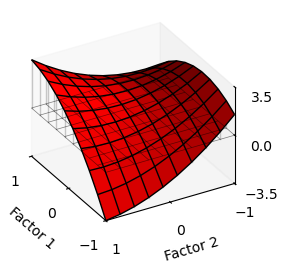

In [32]:
x1 = np.array([-1, 0, 1])
x2 = np.array([-1, 0, 1])
num = 10
x1_, x2_ = np.meshgrid(np.linspace(np.min(x1),np.max(x1),num=num),
                       np.linspace(np.min(x2),np.max(x2),num=num))

y1 = measure_response(x1_, x2_, False)  # True model, no noise

plt.clf()

fig = plt.figure(figsize=(3,3))
ax = fig.add_subplot(1,1,1,projection='3d')
ax.set_proj_type('ortho')
ax.view_init(30, 150)
ax.set_xlim(-1,1)
ax.set_ylim(-1,1)
ax.set_zlim(np.min(y1),np.max(y1))
ax.set_xticks([-1,0,1])
ax.set_yticks([-1,0,1])
ax.set_zticks([np.min(y1),0,np.max(y1)])
ax.grid(False)
ax.set_xlabel("Factor 1")
ax.set_ylabel("Factor 2")
ax.set_zlabel("Response")
ax.plot_wireframe(x1_, x2_, y1*0, linewidth=0.5, color='k', alpha=0.5)
ax.plot_wireframe(x1_, x2_, y1, linewidth=1, color='k')
ax.plot_surface(x1_, x2_, y1, color='r', shade=True)

for xi, yi, zi in zip(x1_.flatten(), x2_.flatten(), y1.flatten()):
    ax.plot([xi, xi], [yi, yi], [0, zi], color='k', alpha=0.2, linewidth=1)

plt.show()

In [33]:
""" OFAT vs Full Factorial """
# OFAT design
x1m_ofat = np.r_[0, np.zeros_like(np.delete(x1, np.where(x1==0))), np.delete(x1, np.where(x1==0))]
x2m_ofat = np.r_[0, np.delete(x1, np.where(x2==0)), np.zeros_like(np.delete(x2, np.where(x2==0)))]
y1m_ofat = measure_response(x1m_ofat, x2m_ofat)  # Measure responses with noise
print("OFAT\n", np.c_[x1m_ofat, x2m_ofat, y1m_ofat])

# Full Factorial design
x1m_ff = np.repeat(x1, x2.shape)
x2m_ff = np.tile(x2, x1.shape)
y1m_ff = measure_response(x1m_ff, x2m_ff)  # Measure responses with noise
print("Full Factorial\n", np.c_[x1m_ff, x2m_ff, y1m_ff])

OFAT
 [[ 0.     0.     0.769]
 [ 0.    -1.     2.555]
 [ 0.     1.     1.36 ]
 [-1.     0.    -1.999]
 [ 1.     0.     0.831]]
Full Factorial
 [[-1.    -1.     1.426]
 [-1.     0.    -1.944]
 [-1.     1.    -3.278]
 [ 0.    -1.     2.721]
 [ 0.     0.     1.08 ]
 [ 0.     1.     1.58 ]
 [ 1.    -1.     0.116]
 [ 1.     0.     1.056]
 [ 1.     1.     3.441]]


<Figure size 640x480 with 0 Axes>

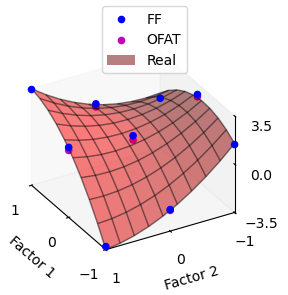

In [34]:
""" Plot OFAT vs Full Factorial """
plt.clf()

fig = plt.figure(figsize=(3,3))
ax = fig.add_subplot(1,1,1,projection='3d')
ax.set_proj_type('ortho')
ax.view_init(30, 150)
ax.set_xlim(np.min(x1),np.max(x1))
ax.set_ylim(np.min(x2),np.max(x2))
ax.set_zlim(np.min(y1),np.max(y1))
ax.set_xticks(x1)
ax.set_yticks(x2)
ax.set_zticks([np.min(y1),0,np.max(y1)])
ax.grid(False)
ax.set_xlabel("Factor 1")
ax.set_ylabel("Factor 2")
ax.set_zlabel("Response")
ax.scatter(x1m_ff, x2m_ff, y1m_ff, color='b', alpha=1, label="FF")
ax.scatter(x1m_ofat, x2m_ofat, y1m_ofat, color='m', alpha=1, label="OFAT")
ax.plot_wireframe(x1_, x2_, y1, linewidth=1, color='k', alpha=0.5)
ax.plot_surface(x1_, x2_, y1, color='r', alpha=0.5, label="Real")
fig.legend(loc="upper center")

plt.show()

[[ 1.    -1.    -1.     1.     1.     1.     1.426]
 [ 1.    -1.     0.     0.     1.     0.    -1.944]
 [ 1.    -1.     1.    -1.     1.     1.    -3.278]
 [ 1.     0.    -1.     0.     0.     1.     2.721]
 [ 1.     0.     0.     0.     0.     0.     1.08 ]
 [ 1.     0.     1.     0.     0.     1.     1.58 ]
 [ 1.     1.    -1.    -1.     1.     1.     0.116]
 [ 1.     1.     0.     0.     1.     0.     1.056]
 [ 1.     1.     1.     1.     1.     1.     3.441]]
β0: 1.1691
β1 (x1): 1.4015
β2 (x2): -0.4199
β3 (x1x2): 2.0072
β4 (x1^2): -1.6577
β5 (x2^2): 0.9372


<Figure size 640x480 with 0 Axes>

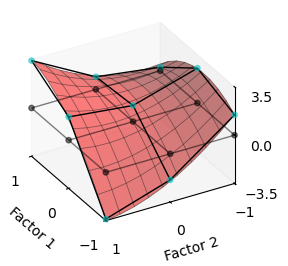

In [35]:
""" Model regression from measured data """
from sklearn.linear_model import LinearRegression

x1m = x1m_ff
x2m = x2m_ff
y1m = y1m_ff

# Design matrix for second-order model
X = np.column_stack((np.ones(x1m.shape),  # intercept
                     x1m,                 # main effect of x1
                     x2m,                 # main effect of x2
                     x1m*x2m,             # interaction x1x2
                     x1m*x1m,             # quadratic effect x1**2
                     x2m*x2m))            # quadratic effect x2**2
print(np.c_[X, y1m])

# Fit regression
model = LinearRegression(fit_intercept=False)  # intercept already in X
model.fit(X, y1m)
betas = model.coef_

# Output coefficients
coeff_labels = ['β0', 'β1 (x1)', 'β2 (x2)', 'β3 (x1x2)', 'β4 (x1^2)', 'β5 (x2^2)']
for label, coef in zip(coeff_labels, betas):
    print(f'{label}: {coef:.4f}')

x1m_grid, x2m_grid = np.meshgrid(np.unique(x1m), np.unique(x2m))
y1m_grid = (betas[0] +
            betas[1]*x1m_grid +
            betas[2]*x2m_grid +
            betas[3]*x1m_grid*x2m_grid +
            betas[4]*x1m_grid*x1m_grid +
            betas[5]*x2m_grid*x2m_grid)

plt.clf()

fig = plt.figure(figsize=(3,3))
ax = fig.add_subplot(1,1,1,projection='3d')
ax.set_proj_type('ortho')
ax.view_init(30, 150)
ax.set_xlim(np.min(x1),np.max(x1))
ax.set_ylim(np.min(x2),np.max(x2))
ax.set_zlim(np.min(y1),np.max(y1))
ax.set_xticks(x1)
ax.set_yticks(x2)
ax.set_zticks([np.min(y1),0,np.max(y1)])
ax.grid(False)
ax.set_xlabel("Factor 1")
ax.set_ylabel("Factor 2")
ax.set_zlabel("Response")
ax.plot_wireframe(x1m_grid, x2m_grid, y1m_grid*0, linewidth=1, color='k', alpha=0.5)
ax.plot_wireframe(x1m_grid, x2m_grid, y1m_grid, linewidth=1, color='k')
ax.scatter(x1m_grid, x2m_grid, y1m_grid*0, s=15, color='k', alpha=0.5)
ax.scatter(x1m_grid, x2m_grid, y1m_grid, s=15, color='c', alpha=0.5)
ax.plot_wireframe(x1_, x2_, y1, linewidth=0.5, color='k', alpha=0.5)
ax.plot_surface(x1_, x2_, y1, color='r', alpha=0.5)

plt.show()

### Lack of Fit Test
Whether simplified models are valid

In [36]:
import pandas as pd

# Factor levels
A_levels = np.array([-1, 0, 1])
B_levels = np.array([-1, 0, 1])

# Number of levels per factor
n_A = len(A_levels)
n_B = len(B_levels)

# Total runs
n_runs = n_A * n_B

# Create the design matrix columns
# For A: repeat each level for B times
A = np.repeat(A_levels, n_B)
# For B: tile for n_A times
B = np.tile(B_levels, n_A)

# Stack columns into a design matrix
design = np.column_stack((A, B))

# Convert to DataFrame for readability
df = pd.DataFrame(design, columns=['A', 'B'])
display(df)

# Apply function row-wise
df['y'] = [measure_response(a, b) for a, b in design]
display(df)

,A,B
0,-1,-1
1,-1,0
2,-1,1
3,0,-1
4,0,0
5,0,1
6,1,-1
7,1,0
8,1,1


,A,B,y
0,-1,-1,1.141222
1,-1,0,-2.251380
2,-1,1,-3.335674
3,0,-1,2.141213
4,0,0,0.685807
5,0,1,1.550633
6,1,-1,0.516306
7,1,0,0.859386
8,1,1,3.572228


In [37]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Fit model with all interactions, including quadratic effects I(X**2)
model = ols('y ~ A + B + A:B + I(A**2) + I(B**2)', data=df).fit()
display(model.params)

# Perform an ANOVA (analysis of variance) (type I sums of squares)
anova_table = sm.stats.anova_lm(model, typ=1)
display(anova_table)

Intercept    0.681629
A            1.565625
B           -0.335259
A:B          1.883205
I(A ** 2)   -1.375536
I(B ** 2)    1.166383
dtype: float64

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,14.707098,14.707098,8572.981010,0.000003
B,1.0,0.674391,0.674391,393.112269,0.000280
A:B,1.0,14.185839,14.185839,8269.131302,0.000003
I(A ** 2),1.0,3.784201,3.784201,2205.865615,0.000021
I(B ** 2),1.0,2.720899,2.720899,1586.051731,0.000035
Residual,3.0,0.005147,0.001716,NaN,NaN


In [38]:
""" Lack of Fit Test """
# Create a reduced model (e.g. without interaction terms)
reduced_model = ols('y ~ A + A:B', data=df).fit()
# Perform an ANOVA (analysis of variance) (type I sums of squares)
anova_table_reduced = sm.stats.anova_lm(reduced_model, typ=1)
print("ANOVA table for Reduced model")
display(anova_table_reduced)

# Perform ANOVA to compare models
anova_results = sm.stats.anova_lm(reduced_model, model)
print("ANOVA Results between Reduced and Full")
display(anova_results)

ANOVA table for Reduced model


,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,14.707098,14.707098,12.282121,0.012755
A:B,1.0,14.185839,14.185839,11.846809,0.013769
Residual,6.0,7.184638,1.197440,NaN,NaN


ANOVA Results between Reduced and Full


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,6.0,7.184638,0.0,NaN,NaN,NaN
1,3.0,0.005147,3.0,7.179491,1395.009872,0.000033
